# Austin Housing Price Prediction (beginner-friendly)

**What this notebook does:** it looks at Austin, TX home sales (data originally from Zillow) and trains models that predict a home's **sale price** from simple facts such as size, bedrooms, school rating and location.

**How to run:** save this notebook in `C:/Users/Administrator/GitHub/PythonProjects/` and choose **Kernel → Restart Kernel and Run All Cells**. If `austinHousingData.csv` is not in that folder, the notebook downloads it automatically.

**Steps**
1. Set up (imports)
2. Load the data
3. Simplify and clean the data (keep only easy numeric columns)
4. Explore the data with charts
5. Split into training and test sets
6. Train three models and compare them
7. Check the best model's mistakes
8. See which features matter
9. Predict the price of your own house

## 1. Set up

We first make sure the four libraries we need are installed, then import them.
* **numpy**: fast maths on arrays of numbers
* **pandas**: tables of data (called DataFrames)
* **matplotlib**: charts
* **scikit-learn**: machine-learning models

In [1]:
import sys, subprocess, importlib                      # tools to check/install packages
for pkg, mod in [("numpy", "numpy"), ("pandas", "pandas"),          # (pip name, import name) pairs we need
                 ("matplotlib", "matplotlib"), ("scikit-learn", "sklearn")]:
    try:                                               # try to import the package
        importlib.import_module(mod)                   # works if it is already installed
    except ImportError:                                # if it is missing...
        print("Installing", pkg)                       # tell the user what is happening
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])  # ...and install it

In [2]:
import os, urllib.request                              # os: file paths; urllib: download a file
import numpy as np                                     # numbers and maths
import pandas as pd                                    # data tables
import matplotlib.pyplot as plt                        # charts
from sklearn.model_selection import train_test_split   # splits data into train/test parts
from sklearn.linear_model import LinearRegression      # model 1: a straight-line style model
from sklearn.ensemble import RandomForestRegressor     # model 2: many decision trees averaged
from sklearn.ensemble import GradientBoostingRegressor # model 3: trees that fix each other's errors
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error  # ways to score a model

RANDOM_STATE = 42                                      # fixed seed so results are the same every run
pd.set_option("display.max_columns", 50)               # show all columns when printing tables

## 2. Load the data

The notebook looks for the CSV file in a few places. If it cannot find it, it downloads a copy from a public GitHub project that stores the Zillow Austin dataset.

In [3]:
FILENAME = "austinHousingData.csv"                     # name of the data file
URL = "https://raw.githubusercontent.com/threnjen/austin_housing_prices/master/" + FILENAME  # public copy

places = [                                             # folders where the file might already be
    FILENAME,                                          # same folder as this notebook
    os.path.join("C:/Users/Administrator/GitHub/PythonProjects", FILENAME),  # your project folder
]
path = next((p for p in places if os.path.exists(p)), None)  # first place that really has the file
if path is None:                                       # not found anywhere
    print("File not found locally, downloading it...") # tell the user
    urllib.request.urlretrieve(URL, FILENAME)          # download it next to the notebook
    path = FILENAME                                    # and use that copy
print("Using file:", os.path.abspath(path))            # show which file is being used

raw = pd.read_csv(path)                                # read the CSV into a table called raw
print("Rows, columns:", raw.shape)                     # how big is the table
raw.head()                                             # show the first 5 rows

File not found locally, downloading it...


Using file: /tmp/t_new/austinHousingData.csv
Rows, columns: (15171, 47)


,zpid,city,streetAddress,zipcode,description,latitude,longitude,propertyTaxRate,garageSpaces,hasAssociation,hasCooling,hasGarage,hasHeating,hasSpa,hasView,homeType,parkingSpaces,yearBuilt,latestPrice,numPriceChanges,latest_saledate,latest_salemonth,latest_saleyear,latestPriceSource,numOfPhotos,numOfAccessibilityFeatures,numOfAppliances,numOfParkingFeatures,numOfPatioAndPorchFeatures,numOfSecurityFeatures,numOfWaterfrontFeatures,numOfWindowFeatures,numOfCommunityFeatures,lotSizeSqFt,livingAreaSqFt,numOfPrimarySchools,numOfElementarySchools,numOfMiddleSchools,numOfHighSchools,avgSchoolDistance,avgSchoolRating,avgSchoolSize,MedianStudentsPerTeacher,numOfBathrooms,numOfBedrooms,numOfStories,homeImage
0,111373431,pflugerville,14424 Lake Victor Dr,78660,"14424 Lake Victor Dr, Pflugerville, TX 78660 i...",30.430632,-97.663078,1.98,2,True,True,True,True,False,False,Single Family,2,2012,305000.0,5,2019-09-02,9,2019,"Coldwell Banker United, Realtors - South Austin",39,0,5,2,1,3,0,1,0,6011.0,2601.0,1,0,1,1,1.266667,2.666667,1063,14,3.0,4,2,111373431_ffce26843283d3365c11d81b8e6bdc6f-p_f...
1,120900430,pflugerville,1104 Strickling Dr,78660,Absolutely GORGEOUS 4 Bedroom home with 2 full...,30.432673,-97.661697,1.98,2,True,True,True,True,False,False,Single Family,2,2013,295000.0,1,2020-10-13,10,2020,Agent Provided,29,0,1,2,0,0,0,0,0,6185.0,1768.0,1,0,1,1,1.400000,2.666667,1063,14,2.0,4,1,120900430_8255c127be8dcf0a1a18b7563d987088-p_f...
2,2084491383,pflugerville,1408 Fort Dessau Rd,78660,Under construction - estimated completion in A...,30.409748,-97.639771,1.98,0,True,True,False,True,False,False,Single Family,0,2018,256125.0,1,2019-07-31,7,2019,Agent Provided,2,0,4,1,0,1,0,0,0,7840.0,1478.0,0,2,1,1,1.200000,3.000000,1108,14,2.0,3,1,2084491383_a2ad649e1a7a098111dcea084a11c855-p_...
3,120901374,pflugerville,1025 Strickling Dr,78660,Absolutely darling one story home in charming ...,30.432112,-97.661659,1.98,2,True,True,True,True,False,False,Single Family,2,2013,240000.0,4,2018-08-08,8,2018,Agent Provided,9,0,0,2,0,0,0,0,0,6098.0,1678.0,1,0,1,1,1.400000,2.666667,1063,14,2.0,3,1,120901374_b469367a619da85b1f5ceb69b675d88e-p_f...
4,60134862,pflugerville,15005 Donna Jane Loop,78660,Brimming with appeal & warm livability! Sleek ...,30.437368,-97.656860,1.98,0,True,True,False,True,False,False,Single Family,0,2002,239900.0,3,2018-10-31,10,2018,Agent Provided,27,0,0,1,0,0,0,0,0,6708.0,2132.0,1,0,1,1,1.133333,4.000000,1223,14,3.0,3,2,60134862_b1a48a3df3f111e005bb913873e98ce2-p_f.jpg


## 3. Simplify and clean the data

The raw file has 47 columns, including text (descriptions, addresses), URLs, dates stored as text and many tiny counts. Those need special handling and add little value, so we **drop them**.

We keep only **11 simple numeric columns** plus the price:

| Column | Meaning |
|---|---|
| `livingAreaSqFt` | indoor living area in square feet |
| `lotSizeSqFt` | land size in square feet |
| `numOfBedrooms`, `numOfBathrooms` | counts |
| `numOfStories` | number of floors |
| `garageSpaces` | cars that fit in the garage |
| `yearBuilt` | year the house was built |
| `avgSchoolRating` | average rating of nearby schools |
| `latitude`, `longitude` | location (north-south, east-west) |
| `latest_saleyear` | year of sale (prices rose over 2018-2021) |
| `latestPrice` | **the sale price we want to predict** |

We also keep only **Single Family** homes (95% of the data). That removes the need to convert house types (text) into numbers, and condos/land behave very differently in price.

In [4]:
keep = ["livingAreaSqFt", "lotSizeSqFt", "numOfBedrooms", "numOfBathrooms", "numOfStories",  # size features
        "garageSpaces", "yearBuilt", "avgSchoolRating", "latitude", "longitude",               # other features
        "latest_saleyear", "latestPrice"]              # sale year and the target (price)
df = raw[raw["homeType"] == "Single Family"][keep].copy()  # keep only single-family rows and our columns
print("Single-family homes:", len(df))                 # how many rows we start with
print("Missing values per column:")                    # check for blanks
print(df.isna().sum().sum(), "missing values in total")  # total number of blank cells

Single-family homes: 14241
Missing values per column:
0 missing values in total


Next we remove rows with **impossible or extreme values** (for example a 1.5 billion sq ft lot). Models learn badly from such errors.

In [5]:
before = len(df)                                       # remember the row count before cleaning
df = df[df["livingAreaSqFt"].between(400, 10000)]      # keep homes between 400 and 10,000 sq ft
df = df[df["lotSizeSqFt"].between(500, 500000)]        # keep lots between 500 sq ft and ~11 acres
df = df[df["latestPrice"].between(50000, 5000000)]     # keep prices between $50k and $5 million
df = df[df["numOfBedrooms"].between(1, 10)]            # keep 1 to 10 bedrooms
df = df[df["numOfBathrooms"].between(1, 10)]           # keep 1 to 10 bathrooms
df = df.reset_index(drop=True)                         # renumber rows 0,1,2,... after removing some
print("Rows removed:", before - len(df), "| Rows kept:", len(df))  # summary of the cleaning

Rows removed: 83 | Rows kept: 14158


Everything left is a plain number, so **no parsing or encoding is needed**. We save this clean table as `austin_housing_clean.csv` so you can reuse it directly in other projects.

In [6]:
df.to_csv("austin_housing_clean.csv", index=False)     # save the clean table to a new CSV file
df.describe().T.round(1)                               # summary statistics (count, mean, min, max...) per column

,count,mean,std,min,25%,50%,75%,max
livingAreaSqFt,14158.0,2215.1,993.2,466.0,1501.0,2008.0,2716.8,9866.0
lotSizeSqFt,14158.0,12008.0,17622.1,1089.0,6621.0,8286.5,10890.0,435600.0
numOfBedrooms,14158.0,3.5,0.8,1.0,3.0,3.0,4.0,8.0
numOfBathrooms,14158.0,2.7,1.0,1.0,2.0,3.0,3.0,10.0
numOfStories,14158.0,1.5,0.5,1.0,1.0,1.0,2.0,4.0
garageSpaces,14158.0,1.2,1.3,0.0,0.0,1.0,2.0,20.0
yearBuilt,14158.0,1988.4,21.5,1905.0,1974.0,1993.0,2006.0,2020.0
avgSchoolRating,14158.0,5.8,1.9,2.3,4.0,5.8,7.0,9.5
latitude,14158.0,30.3,0.1,30.1,30.2,30.3,30.4,30.5
longitude,14158.0,-97.8,0.1,-98.0,-97.8,-97.8,-97.7,-97.6


## 4. Explore the data

Always look at the data before modelling. First, the price distribution.

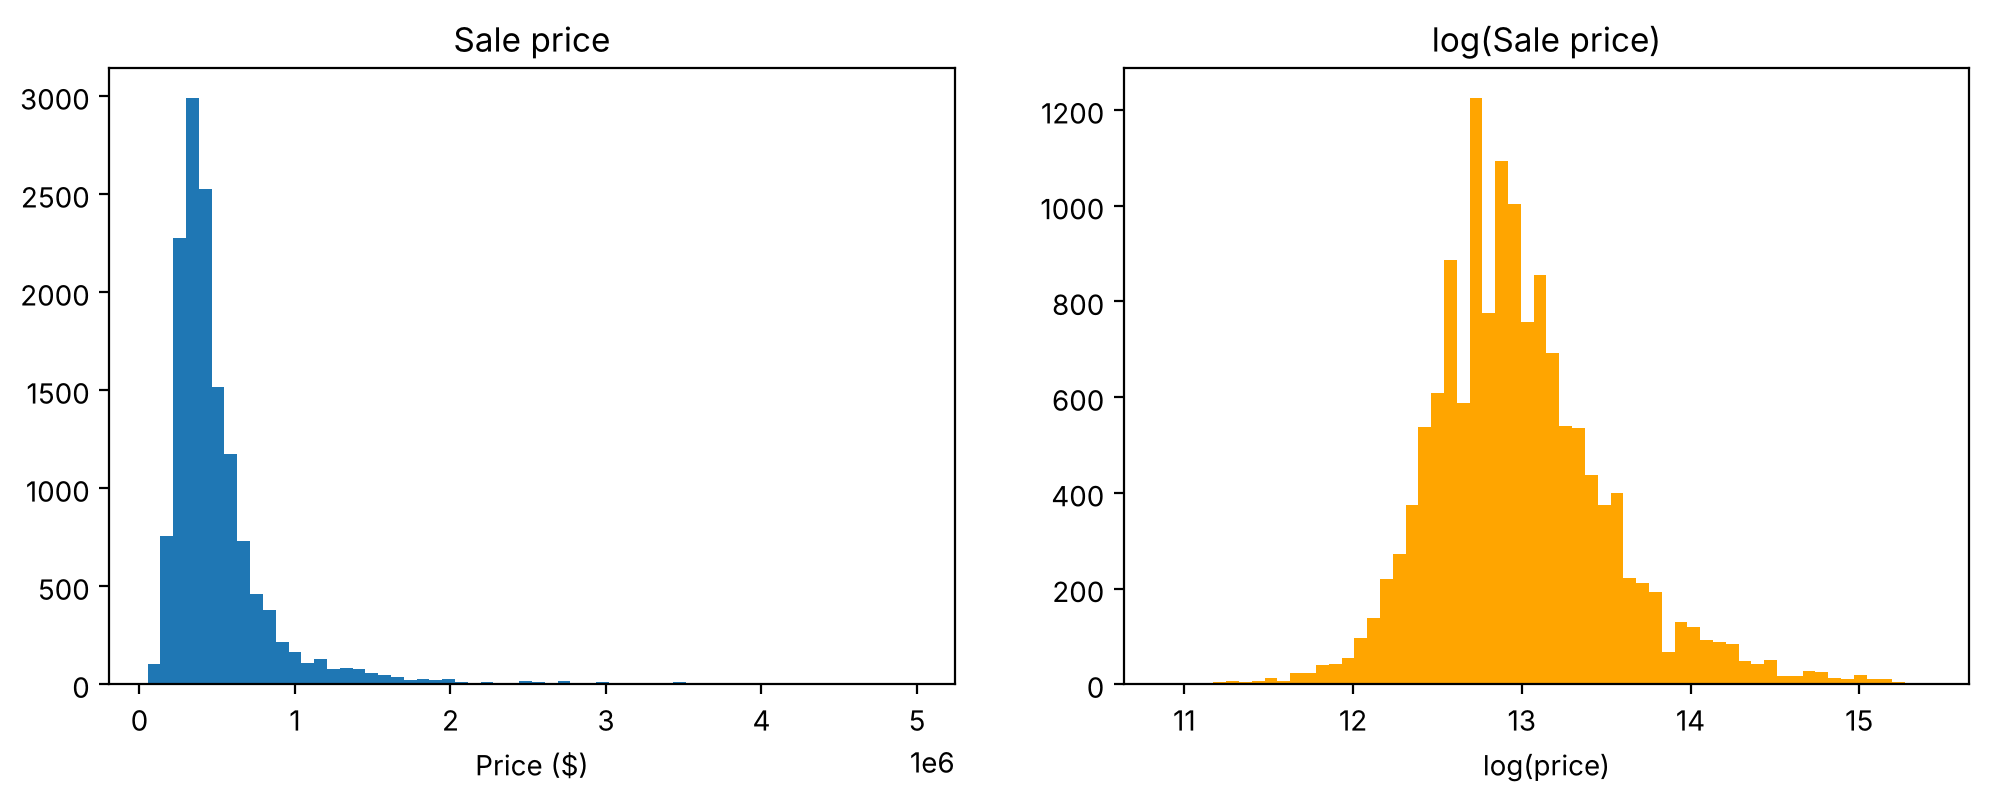

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))        # a figure with two charts side by side
axes[0].hist(df["latestPrice"], bins=60)               # histogram of the raw prices
axes[0].set_title("Sale price")                        # title of the left chart
axes[0].set_xlabel("Price ($)")                        # x-axis label
axes[1].hist(np.log(df["latestPrice"]), bins=60, color="orange")  # histogram of log(price)
axes[1].set_title("log(Sale price)")                   # title of the right chart
axes[1].set_xlabel("log(price)")                       # x-axis label
plt.show()                                             # draw the charts

Prices have a long tail: a few very expensive homes stretch the chart to the right. Taking the **logarithm** makes the shape much more even, which helps models. So we will **predict log(price)** and convert back to dollars afterwards.

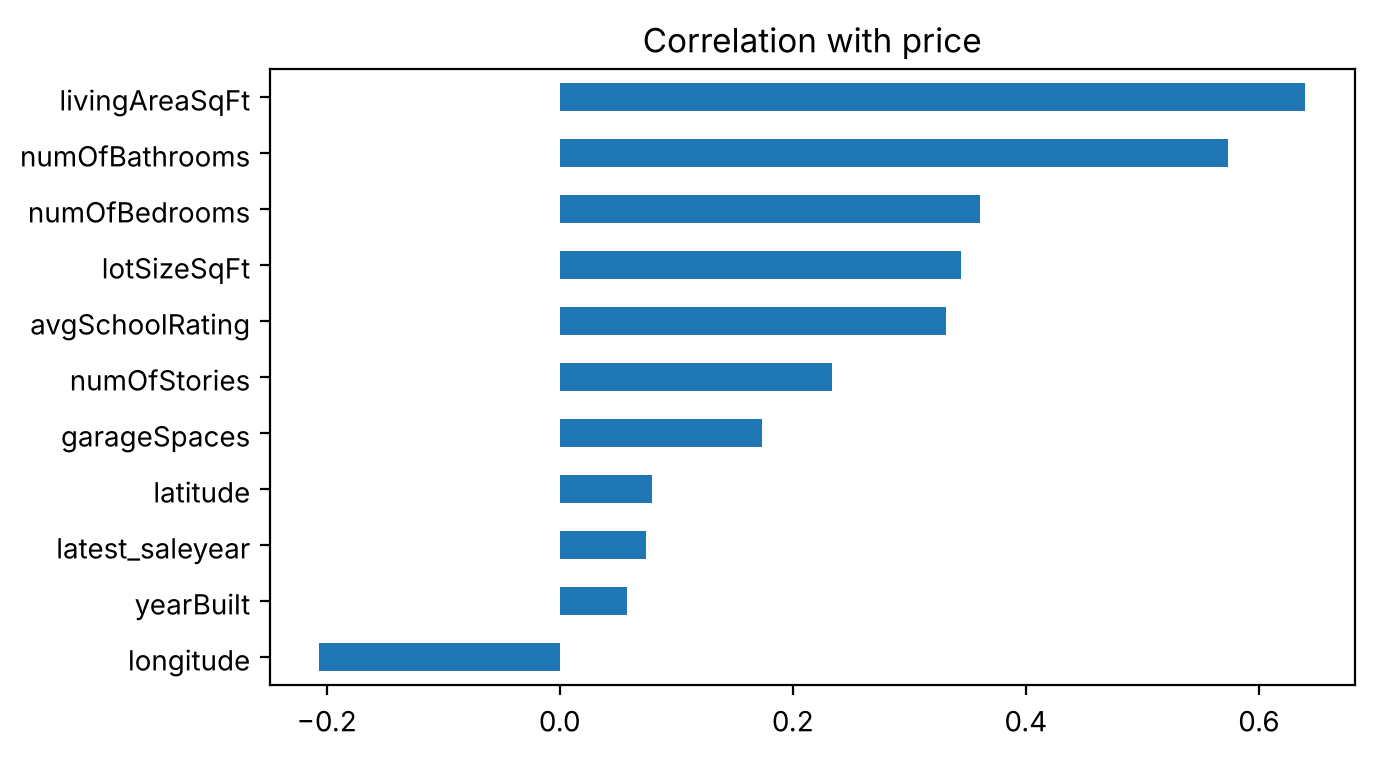

In [8]:
corr = df.corr()["latestPrice"].drop("latestPrice").sort_values()  # correlation of every feature with price
corr.plot(kind="barh", figsize=(7, 4), title="Correlation with price")  # horizontal bar chart
plt.show()                                             # draw it

A correlation near +1 means 'when this goes up, price goes up'. Living area, bathrooms and school rating are the strongest.

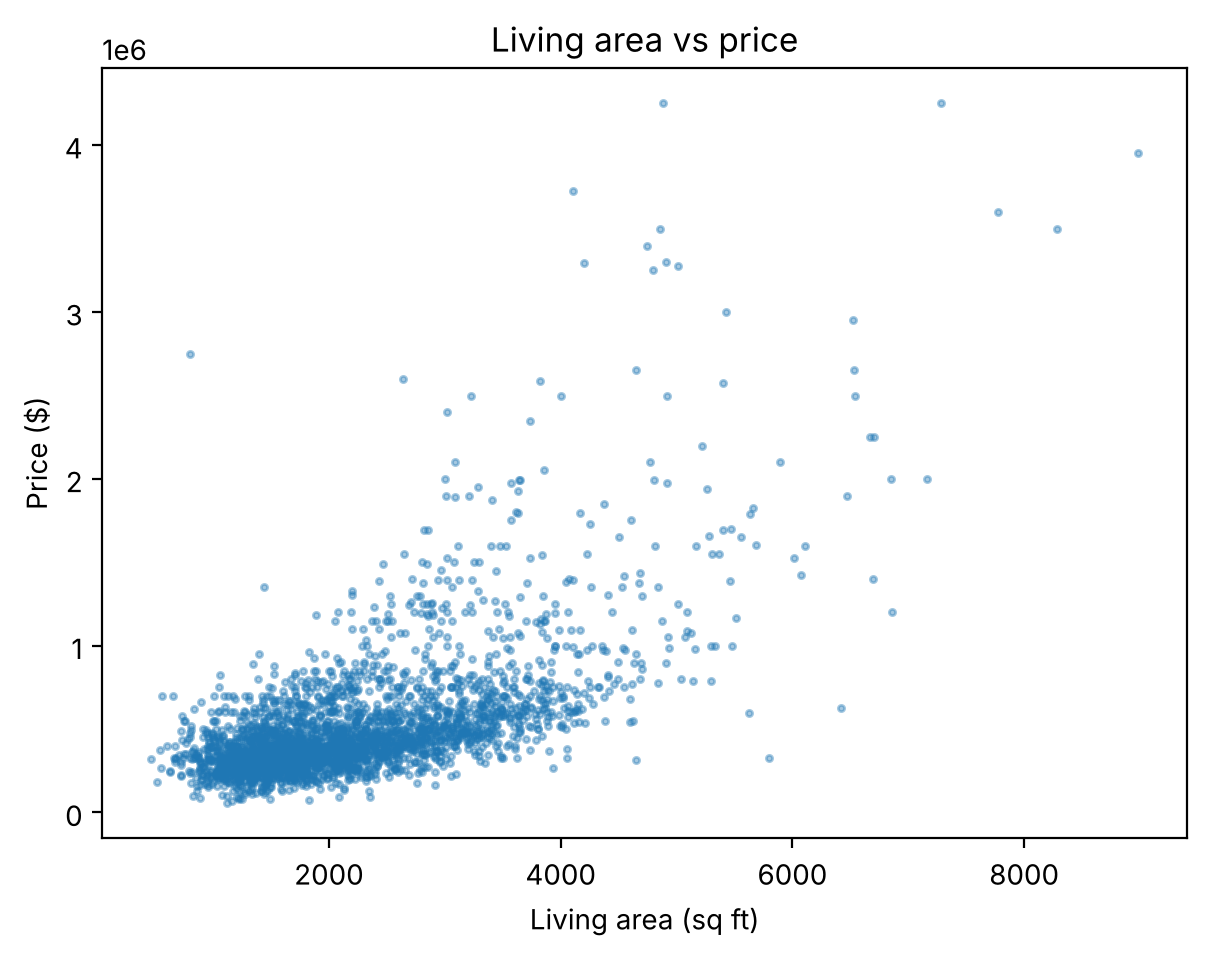

In [9]:
sample = df.sample(3000, random_state=RANDOM_STATE)    # a random 3000 homes so the chart is not crowded
plt.figure(figsize=(7, 5))                             # create a figure
plt.scatter(sample["livingAreaSqFt"], sample["latestPrice"], s=5, alpha=0.4)  # one dot per home
plt.title("Living area vs price")                      # chart title
plt.xlabel("Living area (sq ft)")                      # x label
plt.ylabel("Price ($)")                                # y label
plt.show()                                             # draw it

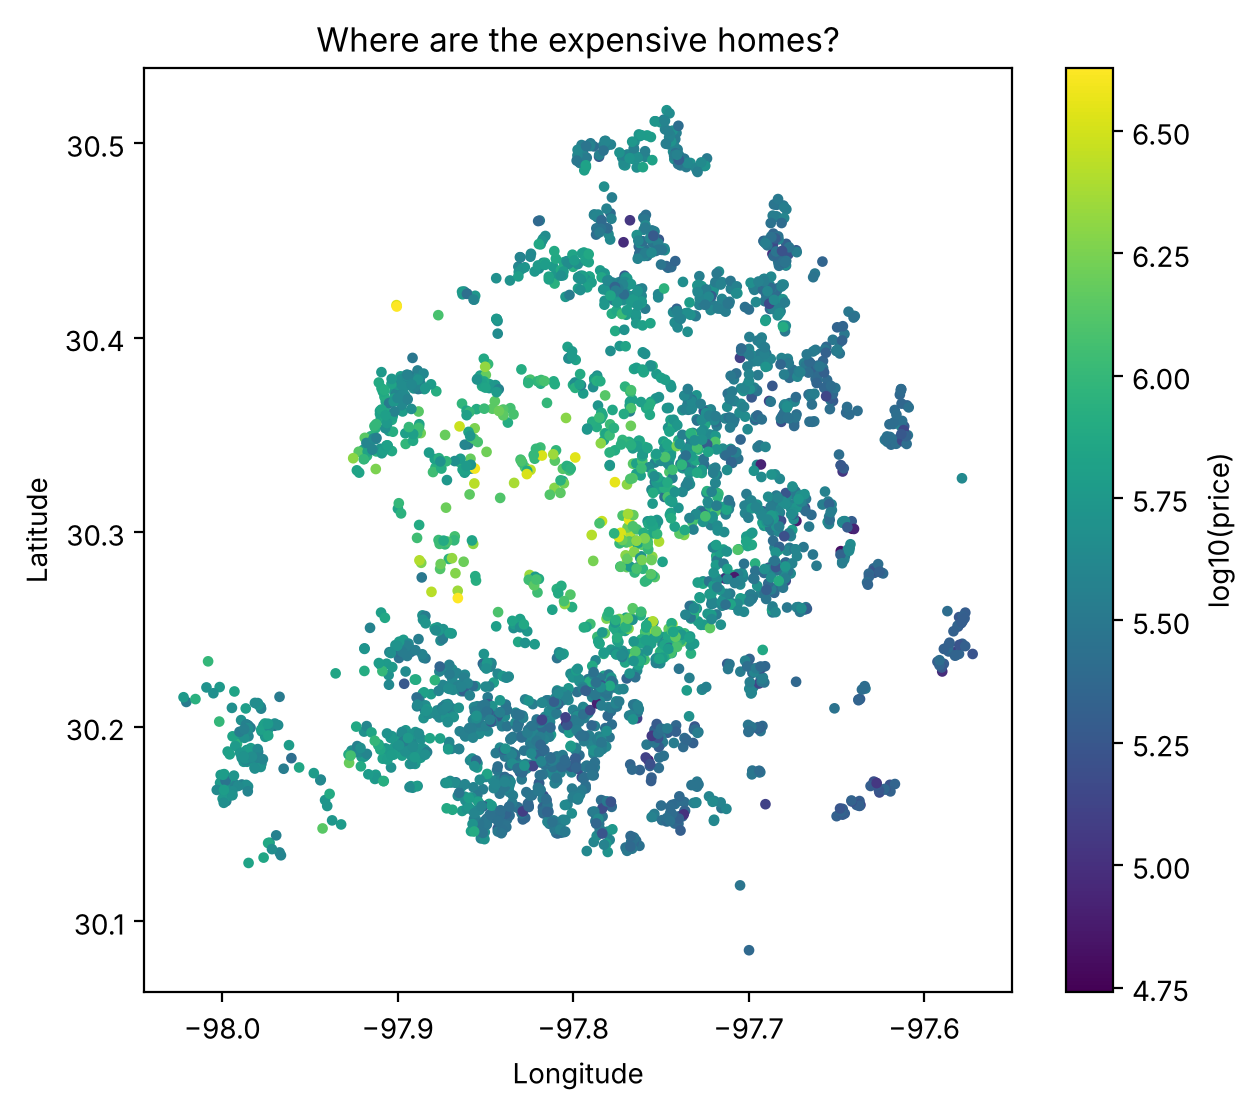

In [10]:
plt.figure(figsize=(7, 6))                             # create a figure for the map
sc = plt.scatter(sample["longitude"], sample["latitude"],  # x = east-west, y = north-south
                 c=np.log10(sample["latestPrice"]), s=8, cmap="viridis")  # colour = price level
plt.colorbar(sc, label="log10(price)")                 # legend for the colours
plt.title("Where are the expensive homes?")            # chart title
plt.xlabel("Longitude")                                # x label
plt.ylabel("Latitude")                                 # y label
plt.show()                                             # draw it

Yellow (expensive) dots cluster in the central and western parts of Austin. Because the model gets latitude and longitude, it can learn this geography by itself.

## 5. Split into training and test sets

* **X** = the inputs (features) the model sees.
* **y** = the answer we want it to predict (log of price).

We hide 20% of homes (the **test set**) while training. Scoring on homes the model never saw tells us how well it will do on new houses.

In [11]:
X = df.drop(columns=["latestPrice"])                   # all columns except price = the features
y = np.log(df["latestPrice"])                          # target = log of price
X_train, X_test, y_train, y_test = train_test_split(   # randomly split the rows
    X, y, test_size=0.2, random_state=RANDOM_STATE)    # 20% for testing, fixed seed for repeatability
print("Training homes:", len(X_train), "| Test homes:", len(X_test))  # sizes of both parts

Training homes: 11326 | Test homes: 2832


## 6. Train three models and compare

* **Linear Regression**: simplest idea, price = weighted sum of features. A good baseline.
* **Random Forest**: 200 decision trees vote; handles non-straight-line patterns.
* **Gradient Boosting**: builds trees one after another, each correcting the previous errors. Usually the most accurate on tables like this.

For each model we: `fit` (learn from training data), `predict` (guess test prices), convert log-prices back to dollars with `np.exp`, and score.

In [12]:
models = {                                             # a dictionary: model name -> model object
    "Linear Regression": LinearRegression(),           # simple baseline
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2,  # 200 trees, leaves need >=2 homes
                                           random_state=RANDOM_STATE, n_jobs=-1),   # n_jobs=-1 uses all CPU cores
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=400, learning_rate=0.05,  # 400 small steps
                                                   max_depth=4, random_state=RANDOM_STATE),  # trees up to 4 levels deep
}
actual = np.exp(y_test)                                # real test prices back in dollars
rows = {}                                              # will hold the scores of each model
predictions = {}                                       # will hold each model's predicted prices

for name, model in models.items():                     # go through the models one by one
    model.fit(X_train, y_train)                        # learn from the training data
    pred = np.exp(model.predict(X_test))               # predict, then convert log-price to dollars
    predictions[name] = pred                           # keep the predictions for later charts
    rows[name] = {                                     # compute the scores for this model
        "R2 (1.0 is perfect)": r2_score(actual, pred),                       # share of price variation explained
        "MAE ($, average miss)": mean_absolute_error(actual, pred),          # average absolute error in dollars
        "RMSE ($)": np.sqrt(mean_squared_error(actual, pred)),               # like MAE but punishes big misses
        "MAPE (% error)": np.mean(np.abs(actual - pred) / actual) * 100,     # average error as a percentage
    }

results = pd.DataFrame(rows).T.round(3)                # turn the scores into a table
results                                                # display the comparison table

,R2 (1.0 is perfect),"MAE ($, average miss)",RMSE ($),MAPE (% error)
Linear Regression,0.517,139162.580,266332.545,26.379
Random Forest,0.769,86943.194,184197.401,17.405
Gradient Boosting,0.749,88809.561,191814.347,17.609


In [13]:
best_name = results["R2 (1.0 is perfect)"].idxmax()    # name of the model with the highest R2
best_model = models[best_name]                         # the fitted model object itself
print("Best model:", best_name)                        # report the winner

Best model: Random Forest


## 7. Check the best model's mistakes

If predictions were perfect, every dot would sit on the red diagonal line.

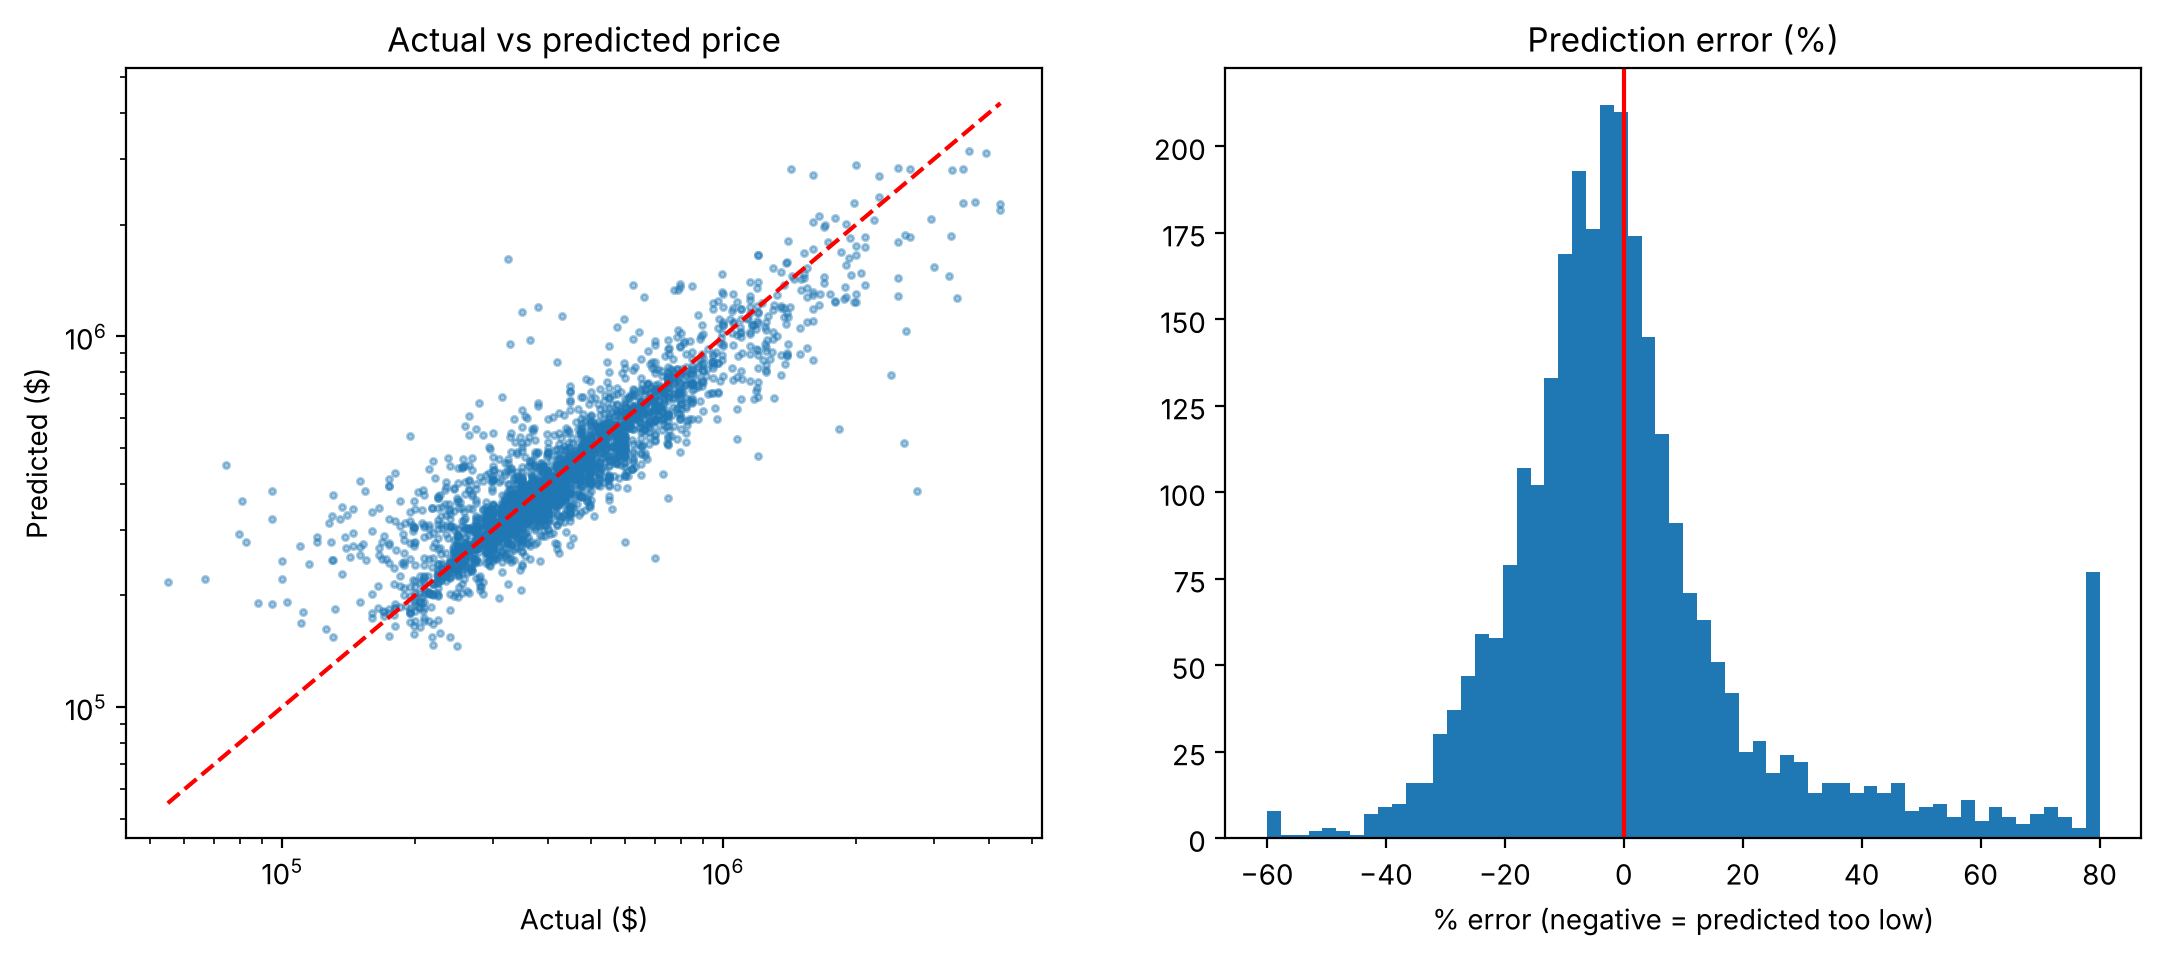

In [14]:
pred = predictions[best_name]                          # predicted prices of the best model
fig, axes = plt.subplots(1, 2, figsize=(13, 5))        # two charts side by side
axes[0].scatter(actual, pred, s=5, alpha=0.4)          # each dot = one test home (actual vs predicted)
low, high = actual.min(), actual.max()                 # price range for the reference line
axes[0].plot([low, high], [low, high], "r--")          # perfect-prediction line
axes[0].set_xscale("log")                              # log scale on x so cheap and costly homes are visible
axes[0].set_yscale("log")                              # log scale on y
axes[0].set_title("Actual vs predicted price")         # title
axes[0].set_xlabel("Actual ($)")                       # x label
axes[0].set_ylabel("Predicted ($)")                    # y label
pct_error = (pred - actual) / actual * 100             # error as a percentage of the true price
axes[1].hist(pct_error.clip(-60, 80), bins=60)         # histogram of % errors (extremes clipped for display)
axes[1].axvline(0, color="r")                          # red line at zero error
axes[1].set_title("Prediction error (%)")              # title
axes[1].set_xlabel("% error (negative = predicted too low)")  # x label
plt.show()                                             # draw the charts

In [15]:
within_10 = np.mean(np.abs(pct_error) <= 10) * 100     # share of predictions within 10% of the true price
within_20 = np.mean(np.abs(pct_error) <= 20) * 100     # share within 20%
print(f"Predictions within 10% of the real price: {within_10:.0f}%")  # print first figure
print(f"Predictions within 20% of the real price: {within_20:.0f}%")  # print second figure

Predictions within 10% of the real price: 50%
Predictions within 20% of the real price: 75%


## 8. Which features matter most?

Tree models can tell us how much each feature helped them make decisions. A longer bar means a more important feature.

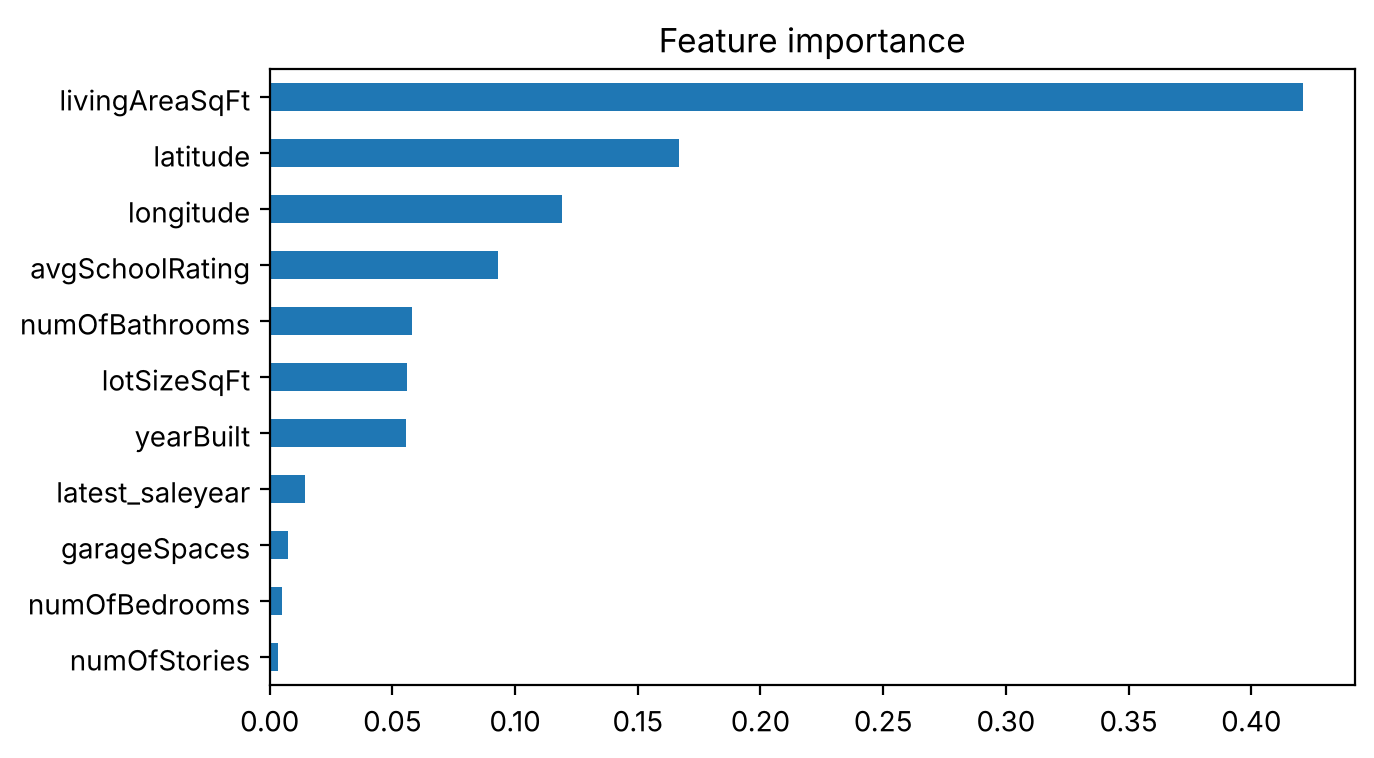

In [16]:
if hasattr(best_model, "feature_importances_"):        # tree models provide importances; linear ones do not
    importance_model = best_model                      # use the best model if it is a tree model
else:
    importance_model = models["Gradient Boosting"]     # otherwise fall back to Gradient Boosting
importance = pd.Series(importance_model.feature_importances_, index=X.columns).sort_values()  # one value per feature
importance.plot(kind="barh", figsize=(7, 4), title="Feature importance")  # horizontal bar chart
plt.show()                                             # draw it

## 9. Predict the price of your own house

Edit the numbers below and run the cell. Use the same units as the data (square feet, and a latitude/longitude inside Austin, e.g. downtown is about 30.27, -97.74).

In [17]:
my_house = pd.DataFrame([{                             # one-row table describing a house
    "livingAreaSqFt": 2200,                            # indoor area in sq ft
    "lotSizeSqFt": 8000,                               # land size in sq ft
    "numOfBedrooms": 4,                                # bedrooms
    "numOfBathrooms": 3,                               # bathrooms
    "numOfStories": 2,                                 # floors
    "garageSpaces": 2,                                 # garage spaces
    "yearBuilt": 2005,                                 # year built
    "avgSchoolRating": 7,                              # average school rating (about 2 to 9)
    "latitude": 30.30,                                 # north-south position
    "longitude": -97.78,                               # east-west position
    "latest_saleyear": 2021,                           # year of sale
}])[X.columns]                                         # put columns in the same order the model was trained on
price = np.exp(best_model.predict(my_house))[0]        # predict log-price, convert to dollars
print(f"Estimated price: ${price:,.0f}")               # show the answer

Estimated price: $833,450


## 10. Summary and limitations

* The model uses only 11 simple numeric features and still explains most of the price variation (see the R² in the comparison table).
* **Location and living area** are the most important drivers.
* The data covers **2018-2021**; Austin prices have changed since, so predictions for today would be outdated unless the model is retrained on recent sales.
* Features like renovation quality, view and neighbourhood are not in these columns, so some error is unavoidable.